# Titanic verisiyle Decision Tree öğrenme

Bu notebook'un amacı bir Kaggle skoru elde etmek değil, **Decision Tree (Karar Ağacı)** modelinin nasıl çalıştığını adım adım öğrenmektir.

Tahmin etmek istediğimiz sütun **Survived** sütunudur:
- `0`: Hayatta kalmadı
- `1`: Hayatta kaldı

Model; yaş, cinsiyet ve bilet sınıfı gibi yolcu özelliklerini kullanarak `Survived` değerini tahmin etmeye çalışacaktır.

## Gini ve entropy neyi ölçer?

İkisi de bir grubun ne kadar **karışık** olduğunu ölçer. Bir düğümde yalnızca hayatta kalanlar veya yalnızca hayatını kaybedenler varsa grup saftır. İki sınıf birbirine yakın sayılardaysa grup karışıktır.

Karar ağacı, veriyi bölerken çocuk grupların saflığını artıran soruları tercih eder. Şimdilik formülleri ezberlememiz gerekmiyor; modelde varsayılan ölçüt olan **Gini** ile başlayacağız.

In [124]:
import pandas as pd # Gelişmiş Dataframe
import numpy as np # Dizilerde gelişmiş sayısal işlemler
import matplotlib.pyplot as plt # Görselleştirme aracı
import seaborn as sns # plt'den daha iyi görselleştirme

In [125]:
%matplotlib inline
sns.set_style("whitegrid")
plt.style.use("fivethirtyeight")

## Adım 1 — Veriyi yükleme ve ilk gözlem

Önce veriyi modele vermeden tanıyacağız. `df.head()` tablonun ilk 5 satırını gösterir. Bu aşamada yalnızca sütunların ne ifade ettiğini ve hedef değişkenimizin hangisi olduğunu anlamaya odaklanıyoruz.

In [126]:
df = pd.read_csv("./data/train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<Axes: xlabel='Survived', ylabel='count'>

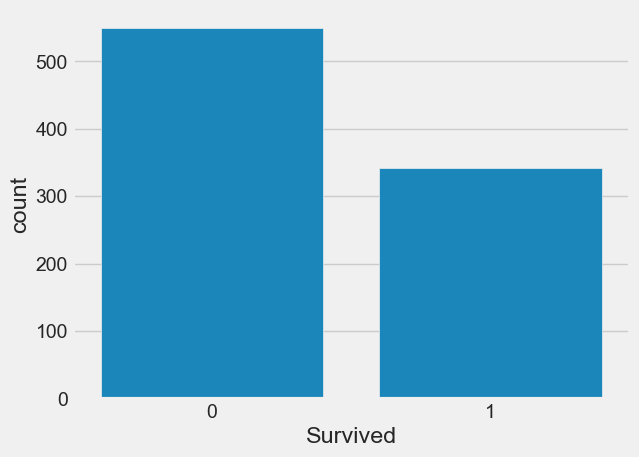

In [127]:
sns.countplot(x='Survived', data=df)

In [128]:
# Label Encoding - One hot Encoding
df['Cabin'].unique()

<StringArray>
[          nan,         'C85',        'C123',         'E46',          'G6',
        'C103',         'D56',          'A6', 'C23 C25 C27',         'B78',
 ...
        'B102',         'B69',         'E49',         'C47',         'D28',
         'E17',         'A24',         'C50',         'B42',        'C148']
Length: 148, dtype: str

In [129]:
'''
1. Encode yapılacak kolonların seçilmesi
2. Encode tipinin seçilmesi
3. Encode'un yapılması
...
Model Eğitimi
...
'''

"\n1. Encode yapılacak kolonların seçilmesi\n2. Encode tipinin seçilmesi\n3. Encode'un yapılması\n...\nModel Eğitimi\n...\n"

In [130]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [131]:

non_numeric_df = df.select_dtypes(exclude=["int64", "float64"])
print(non_numeric_df.head())
print(non_numeric_df.columns)

                                                Name     Sex  \
0                            Braund, Mr. Owen Harris    male   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female   
2                             Heikkinen, Miss. Laina  female   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female   
4                           Allen, Mr. William Henry    male   

             Ticket Cabin Embarked  
0         A/5 21171   NaN        S  
1          PC 17599   C85        C  
2  STON/O2. 3101282   NaN        S  
3            113803  C123        S  
4            373450   NaN        S  
Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='str')


In [132]:
print(df['Name'].unique())

<StringArray>
[                            'Braund, Mr. Owen Harris',
 'Cumings, Mrs. John Bradley (Florence Briggs Thayer)',
                              'Heikkinen, Miss. Laina',
        'Futrelle, Mrs. Jacques Heath (Lily May Peel)',
                            'Allen, Mr. William Henry',
                                    'Moran, Mr. James',
                             'McCarthy, Mr. Timothy J',
                      'Palsson, Master. Gosta Leonard',
   'Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)',
                 'Nasser, Mrs. Nicholas (Adele Achem)',
 ...
                                  'Markun, Mr. Johann',
                        'Dahlberg, Miss. Gerda Ulrika',
                       'Banfield, Mr. Frederick James',
                              'Sutehall, Mr. Henry Jr',
                'Rice, Mrs. William (Margaret Norton)',
                               'Montvila, Rev. Juozas',
                        'Graham, Miss. Margaret Edith',
            'Johnston, Miss. 

In [133]:
print(df['Sex'].unique())

<StringArray>
['male', 'female']
Length: 2, dtype: str


In [134]:
# Label Encode

In [135]:

print(df['Ticket'].unique())
print('-'*20 + '^-^' + '-'*20)
print(df[df['Ticket'].isna()])
print('-'*20 + '^-^' + '-'*20)


<StringArray>
[       'A/5 21171',         'PC 17599', 'STON/O2. 3101282',
           '113803',           '373450',           '330877',
            '17463',           '349909',           '347742',
           '237736',
 ...
           '349212',           '349217',           '349257',
             '7552', 'C.A./SOTON 34068',  'SOTON/OQ 392076',
           '211536',           '112053',           '111369',
           '370376']
Length: 681, dtype: str
--------------------^-^--------------------
Empty DataFrame
Columns: [PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked]
Index: []
--------------------^-^--------------------


In [136]:
df.loc[df['Ticket'].duplicated(keep=False), ['Name', 'Ticket']].sort_values('Ticket')

,Name,Ticket
257,"Cherry, Miss. Gladys",110152
759,"Rothes, the Countess. of (Lucy Noel Martha Dye...",110152
504,"Maioni, Miss. Roberta",110152
262,"Taussig, Mr. Emil",110413
558,"Taussig, Mrs. Emil (Tillie Mandelbaum)",110413
...,...,...
736,"Ford, Mrs. Edward (Margaret Ann Watson)",W./C. 6608
86,"Ford, Mr. William Neal",W./C. 6608
147,"Ford, Miss. Robina Maggie ""Ruby""",W./C. 6608
540,"Crosby, Miss. Harriet R",WE/P 5735


In [137]:

print(df['Cabin'].unique())

<StringArray>
[          nan,         'C85',        'C123',         'E46',          'G6',
        'C103',         'D56',          'A6', 'C23 C25 C27',         'B78',
 ...
        'B102',         'B69',         'E49',         'C47',         'D28',
         'E17',         'A24',         'C50',         'B42',        'C148']
Length: 148, dtype: str


In [138]:

print(df['Embarked'].unique())

<StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str


In [139]:
df[df['Embarked'].isna() & df['Cabin'].notna()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


In [140]:
df[df['Cabin'] == 'B28']

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


In [141]:
df[df['Embarked'].isna()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


In [142]:
'''
15 Ağustos 2026
Günü nasıl kapattık:
1. EDA yaptık.
2. Henüz encode etme işimiz bitmedi. Sex alanına baktık. Ticke alanına değerlendirmeyi bitirmek üzereyiz.
3. Cabin ve Embark ilişkisini gözlemledik.
'''

'\n15 Ağustos 2026\nGünü nasıl kapattık:\n1. EDA yaptık.\n2. Henüz encode etme işimiz bitmedi. Sex alanına baktık. Ticke alanına değerlendirmeyi bitirmek üzereyiz.\n3. Cabin ve Embark ilişkisini gözlemledik.\n'

In [143]:
df.loc[df['Cabin'].duplicated(keep=False), ['Name', 'Cabin', 'Ticket']].sort_values('Cabin')

,Name,Cabin,Ticket
329,"Hippach, Miss. Jean Gertrude",B18,111361
523,"Hippach, Mrs. Louis Albert (Ida Sophia Fischer)",B18,111361
781,"Dick, Mrs. Albert Adrian (Vera Gillespie)",B20,17474
690,"Dick, Mr. Albert Adrian",B20,17474
745,"Crosby, Capt. Edward Gifford",B22,WE/P 5735
...,...,...,...
884,"Sutehall, Mr. Henry Jr",NaN,SOTON/OQ 392076
885,"Rice, Mrs. William (Margaret Norton)",NaN,382652
886,"Montvila, Rev. Juozas",NaN,211536
888,"Johnston, Miss. Catherine Helen ""Carrie""",NaN,W./C. 6607


In [144]:
'''
Feature Engineering kapsamında cabin ve ticket featurelarını inceledik. Her kabine ait bir ticket olduğunu gördük. 
Bu da cabin ve ticket featurelarının birbirlerini açıkladığını ifade eder. Yani bu iki featuredan birini kullanmak model için yeterlidir.
'''

cabinde_farkli_ticket = df[df['Cabin'].notna() & df.groupby('Cabin')['Ticket'].transform('nunique') > 1].sort_values(['Cabin', 'Ticket'])
cabinde_farkli_ticket

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [145]:
'''
Encode işlemin boş değer olmaz.
Boş olan değerler veri setimiz için anlamlı olabilir. Boş sayısı çok olmadığı için doldurmaya karar verdik.
Ayırt edebilmek için gerçek verinin dışında bir harf ile ifade ettik.
'''

df['Embarked'] = df['Embarked'].fillna('Z')

In [146]:
# One Hot Encode
df_one_hot_encode = pd.get_dummies(df, columns=['Sex', 'Embarked'], dtype=int, drop_first=True)
df_one_hot_encode

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Sex_male,Embarked_Q,Embarked_S,Embarked_Z
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,1,0,1,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,0,0,0,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,0,0,1,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,0,0,1,0
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,NaN,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",27.0,0,0,211536,13.0000,NaN,1,0,1,0
887,888,1,1,"Graham, Miss. Margaret Edith",19.0,0,0,112053,30.0000,B42,0,0,1,0
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",NaN,1,2,W./C. 6607,23.4500,NaN,0,0,1,0
889,890,1,1,"Behr, Mr. Karl Howell",26.0,0,0,111369,30.0000,C148,1,0,0,0


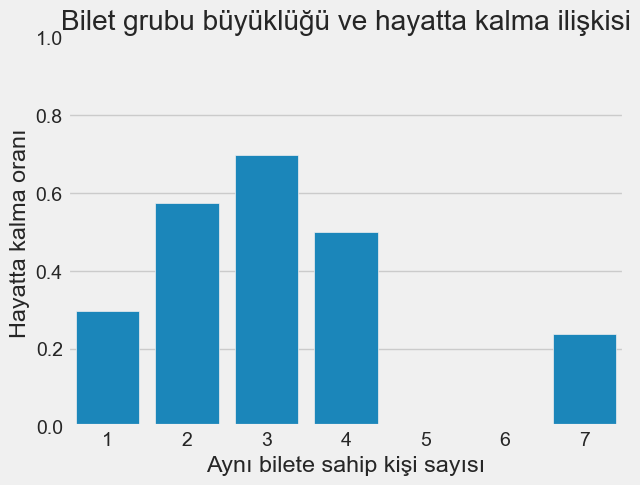

In [147]:
df['TicketGroupSize'] = df.groupby('Ticket')['Ticket'].transform('size')

sns.barplot(
    data=df,
    x='TicketGroupSize',
    y='Survived',
    errorbar=None
)

plt.xlabel("Aynı bilete sahip kişi sayısı")
plt.ylabel("Hayatta kalma oranı")
plt.title("Bilet grubu büyüklüğü ve hayatta kalma ilişkisi")
plt.ylim(0, 1)
plt.show()

In [148]:
ticket_ozet = df.groupby('TicketGroupSize').agg(
    PassengerCount=('Survived', 'size'),
    TicketCount=('Ticket','nunique'),
    SurvivedRate=('Survived', 'mean')
)

ticket_ozet

,PassengerCount,TicketCount,SurvivedRate
TicketGroupSize,,,
1,547,547,0.297989
2,188,94,0.574468
3,63,21,0.698413
4,44,11,0.500000
5,10,2,0.000000
6,18,3,0.000000
7,21,3,0.238095


In [149]:
df[['TicketGroupSize', 'PassengerId']]

,TicketGroupSize,PassengerId
0,1,1
1,1,2
2,1,3
3,2,4
4,1,5
...,...,...
886,1,887
887,1,888
888,2,889
889,1,890


In [150]:
numeric_df = df_one_hot_encode.drop([col for col in non_numeric_df.columns if col not in ['Sex', 'Embarked']], axis=1)
numeric_df['TicketGroupSize'] = df['TicketGroupSize']
numeric_df[['TicketGroupSize', 'PassengerId']]

,TicketGroupSize,PassengerId
0,1,1
1,1,2
2,1,3
3,2,4
4,1,5
...,...,...
886,1,887
887,1,888
888,2,889
889,1,890


In [151]:
df.index.equals(numeric_df.index)

True


# Neler oldu:
- Encode işlemi tamamlandı. Kullanılamayacak alanlar ayıklandı.
- Ticket kolonunda yeni özellik üretildi. (TicketGroupSize)
# Ne olacak:
- Name'den özellik çıkarılacak.
- Model eğitmeye çalışacağız.